# 04 · Part 4: hard geometry

**Question.** When Gaussian noise blurs the structure of SIFT, so that a query's nearest neighbour is barely closer than a typical vector, how much does each index break, and which breaks first? The hypothesis is in `hypothesis.md`, committed before this notebook first ran. The next cell refuses to continue unless that commit exists.

**Setup.** One property changes: the noise level σ, the standard deviation of the added noise as a multiple of the data's spread. σ = 0 is the unchanged control; 0.1, 0.3 and 1.0 are the three noisy settings. Base size, queries, index settings and the noise pattern stay the same; only σ scales it. Each setting gets its own ground truth, and both indexes are rebuilt on it. Choices are recorded in `design_note.md`.

In [1]:
%run ./00_core.ipynb

.

.

.

.

.

...

                                                                                         [100%]


.

.

                                                                                           [100%]

mode=full  results -> results  timing CPU 2  build threads 12


In [2]:
require_committed_hypothesis("Part 4")

Part 4 hypothesis committed in 52debec 2026-10-23 17:30:25 +0530


## The generator
`add_noise` adds σ · s · ε to every base vector and query, where s is the mean per-coordinate standard deviation of the clean base set and ε ~ N(0, I). The noise comes from a seeded generator: base noise first, then query noise, so the two are independent, and the same seed gives the same ε at every σ. The settings therefore differ only in how strongly that one noise pattern is scaled.

In [3]:
def data_spread(base):
    """s: the mean per-coordinate standard deviation of the clean base vectors."""
    return float(base.astype(np.float64).std(axis=0).mean())


def add_noise(base, queries, sigma, seed=SEED, spread=None):
    """Base vectors and queries with seeded Gaussian noise of standard deviation sigma * s on every coordinate."""
    spread = data_spread(base) if spread is None else spread
    rng = np.random.default_rng(seed)
    base_noise = rng.standard_normal(base.shape, dtype=np.float32)
    query_noise = rng.standard_normal(queries.shape, dtype=np.float32)
    scale = np.float32(sigma * spread)
    return base + scale * base_noise, queries + scale * query_noise

In [4]:
%%ipytest -qq

def toy_vectors():
    rng = np.random.default_rng(0)
    return rng.uniform(0, 100, (4_000, 16)).astype(np.float32), rng.uniform(0, 100, (50, 16)).astype(np.float32)


def test_same_seed_gives_identical_data():
    base, queries = toy_vectors()
    first, second = add_noise(base, queries, 0.3, seed=7), add_noise(base, queries, 0.3, seed=7)
    assert all(np.array_equal(a, b) for a, b in zip(first, second))


def test_different_seed_gives_different_data():
    base, queries = toy_vectors()
    assert not np.array_equal(add_noise(base, queries, 0.3, seed=7)[0], add_noise(base, queries, 0.3, seed=8)[0])


def test_sigma_zero_is_the_unchanged_control():
    base, queries = toy_vectors()
    noisy_base, noisy_queries = add_noise(base, queries, 0.0)
    assert np.array_equal(noisy_base, base) and np.array_equal(noisy_queries, queries)


def test_shapes_and_dtype_are_kept_and_inputs_untouched():
    base, queries = toy_vectors()
    before = base.copy()
    noisy_base, noisy_queries = add_noise(base, queries, 1.0)
    assert noisy_base.shape == base.shape and noisy_queries.shape == queries.shape
    assert noisy_base.dtype == np.float32 and noisy_queries.dtype == np.float32
    assert np.array_equal(base, before)


def test_noise_has_the_requested_scale():
    base, queries = toy_vectors()
    noisy_base, _ = add_noise(base, queries, 0.3)
    assert (noisy_base - base).std() == pytest.approx(0.3 * data_spread(base), rel=0.02)


def test_one_noise_pattern_is_scaled_by_sigma():
    base, queries = toy_vectors()
    low, high = add_noise(base, queries, 0.1)[0] - base, add_noise(base, queries, 1.0)[0] - base
    assert np.allclose(10 * low, high, atol=1e-2)


def test_base_and_query_noise_are_different_draws():
    base, _ = toy_vectors()
    noisy_base, noisy_queries = add_noise(base, base.copy(), 1.0)
    assert not np.array_equal(noisy_base, noisy_queries)

.

.

.

.

.

.

.

                                                                                      [100%]

## Relative contrast
For one query, relative contrast is the mean distance to the base vectors divided by the distance to its nearest neighbour. Near 1, the nearest neighbour is barely closer than a typical vector. The mean is taken over 1,000 base vectors sampled with a fixed seed, and the nearest neighbour comes from the ground truth. Distances are plain L2, computed in float64.

In [5]:
def relative_contrast(base, queries, nearest_ids, sample=1_000, seed=SEED):
    """Per query: mean L2 distance to `sample` seeded random base vectors / L2 distance to its nearest neighbour."""
    picked = base[np.random.default_rng(seed).choice(len(base), size=min(sample, len(base)), replace=False)]
    q, x = queries.astype(np.float64), picked.astype(np.float64)
    squared = (q ** 2).sum(1)[:, None] + (x ** 2).sum(1)[None, :] - 2 * q @ x.T
    mean = np.sqrt(np.maximum(squared, 0)).mean(1)
    nearest = np.linalg.norm(q - base[nearest_ids].astype(np.float64), axis=1)
    return mean / nearest

In [6]:
%%ipytest -qq

def test_relative_contrast_on_a_known_layout():
    base = np.array([[1, 0], [3, 0]], dtype=np.float32)        # distances 1 and 3 from the query
    query = np.zeros((1, 2), dtype=np.float32)
    assert relative_contrast(base, query, np.array([0]), sample=2) == pytest.approx([2.0])


def test_noise_lowers_relative_contrast():
    base, queries = toy_vectors()
    contrast = []
    for sigma in (0.0, 1.0):
        noisy_base, noisy_queries = add_noise(base, queries, sigma)
        nearest = exact_knn(noisy_base, noisy_queries, 1)[1][:, 0]
        contrast.append(np.median(relative_contrast(noisy_base, noisy_queries, nearest)))
    assert contrast[1] < contrast[0]

.

.

                                                                                           [100%]

## Configurations
The sweeps are longer than in Part 2: efSearch goes up to 2048, and nprobe up to nlist, which scans every list. In the worst case IVF-Flat can therefore always reach 0.95, by scanning everything.

In [7]:
def noise_configs(config=CONFIG):
    """(index kind, build settings, search values), the same at every noise level."""
    return [("ivf_flat", dict(nlist=config["noise_nlist"]), config["noise_nprobe"]),
            ("hnsw", dict(M=config["noise_M"], efC=config["hnsw_efC"]), config["noise_ef_search"])]


print(f"{CONFIG['noise_n_base']:,} base vectors; sigma in {CONFIG['noise_sigmas']}")
pd.DataFrame([dict(index=kind, build=json.dumps(params), search=f"{SEARCH_PARAM[kind]} {values[0]} to {values[-1]}")
              for kind, params, values in noise_configs()])

150,000 base vectors; sigma in [0.0, 0.1, 0.3, 1.0]


,index,build,search
0,ivf_flat,"{""nlist"": 1024}",nprobe 1 to 1024
1,hnsw,"{""M"": 16, ""efC"": 200}",efSearch 10 to 2048


## Run
Each noise level's rows are written as soon as they are measured. Every row also stores σ, the data spread s, and that level's relative contrast.

In [8]:
clean = load_dataset("sift", CONFIG["noise_n_base"])
spread = data_spread(clean.base)
print(f"data spread s = {spread:.3f}")
for sigma in CONFIG["noise_sigmas"]:
    started = time.perf_counter()
    base, queries = add_noise(clean.base, clean.queries, sigma, spread=spread)
    data = Dataset("sift", base, queries, None, None)
    gt = ground_truth("sift_noise", base, queries)
    contrast = float(np.median(relative_contrast(base, queries[REPORT], gt[REPORT, 0])))
    variant = f"sigma={sigma:g}"
    rows = benchmark_exact(4, variant, data, gt, variant=variant)
    for kind, params, values in noise_configs():
        rows += benchmark_index(4, variant, data, gt, kind, params, values, variant=variant)
    rows = [dict(row, sigma=sigma, data_spread=spread, relative_contrast=contrast) for row in rows]
    write_rows(rows, part=4, section=variant)
    print(f"{variant}: relative contrast {contrast:.3f}, {len(rows)} rows in {(time.perf_counter() - started) / 60:.1f} min")
    del base, queries, data, gt
del clean

data spread s = 32.747


sigma=0 sigma=0 ivf_flat {'nlist': 1024}: built in 1.7 s, best tune recall 0.998


sigma=0 sigma=0 hnsw {'M': 16, 'efC': 200}: built in 4.4 s, best tune recall 0.998
sigma=0: relative contrast 2.423, 43 rows in 1.2 min


sigma=0.1 sigma=0.1 ivf_flat {'nlist': 1024}: built in 1.7 s, best tune recall 0.998


sigma=0.1 sigma=0.1 hnsw {'M': 16, 'efC': 200}: built in 4.4 s, best tune recall 0.997
sigma=0.1: relative contrast 2.381, 43 rows in 1.2 min


sigma=0.3 sigma=0.3 ivf_flat {'nlist': 1024}: built in 1.8 s, best tune recall 0.996


sigma=0.3 sigma=0.3 hnsw {'M': 16, 'efC': 200}: built in 4.6 s, best tune recall 0.996
sigma=0.3: relative contrast 2.125, 43 rows in 1.2 min


sigma=1 sigma=1 ivf_flat {'nlist': 1024}: built in 1.8 s, best tune recall 0.998


sigma=1 sigma=1 hnsw {'M': 16, 'efC': 200}: built in 5.7 s, best tune recall 0.998
sigma=1: relative contrast 1.522, 63 rows in 5.9 min


## What the noise did
Left: relative contrast at each σ, which checks that the manipulation did what it was meant to. Middle: report-half recall when each index keeps the setting that reached 0.95 on the control. Right: QPS at each σ's own operating point for 0.95, with exact search as the control for cost.

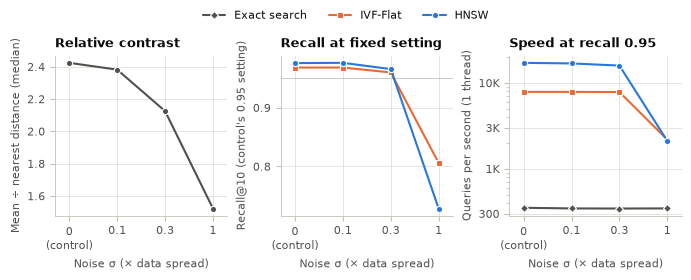

In [9]:
results = read_results()
figure, tables = part4_assets(results)
plt.show()

In [10]:
for name, table in tables.items():
    print(name)
    display(table)

part4_noise


,σ,Rel. contrast,Method,Setting for 0.95,Recall,QPS,Distances/query,Recall at control's setting
0,0,2.423,Exact search,full scan,1.000,351,"150,000",
1,0,2.423,IVF-Flat,"nlist=1024, nprobe=32",0.968,"7,862","6,101",0.968
2,0,2.423,HNSW,"M=16, efSearch=48",0.976,"17,123",843,0.976
3,0.1,2.381,Exact search,full scan,1.000,345,"150,000",
4,0.1,2.381,IVF-Flat,"nlist=1024, nprobe=32",0.968,"7,859","6,115",0.968
5,0.1,2.381,HNSW,"M=16, efSearch=48",0.976,"16,858",850,0.976
6,0.3,2.125,Exact search,full scan,1.000,344,"150,000",
7,0.3,2.125,IVF-Flat,"nlist=1024, nprobe=32",0.960,"7,827","6,101",0.960
8,0.3,2.125,HNSW,"M=16, efSearch=48",0.966,"15,912",931,0.966
9,1,1.522,Exact search,full scan,1.000,346,"150,000",


In [11]:
%%ipytest -qq

noise = noise_table(results)


def test_every_noise_level_has_all_three_methods():
    assert sorted(noise["sigma"].unique()) == CONFIG["noise_sigmas"]
    assert all(set(methods) == {"exact", "ivf_flat", "hnsw"} for methods in noise.groupby("sigma")["index"].agg(set))


def test_relative_contrast_falls_as_noise_grows():
    contrast = noise.drop_duplicates("sigma").sort_values("sigma")["relative_contrast"]
    assert contrast.is_monotonic_decreasing


def test_ivf_flat_always_gets_back_to_095_by_scanning_more_lists():
    assert (noise.loc[noise["index"] == "ivf_flat", "setting"] != "not reached").all()


def test_exact_search_does_the_same_work_at_every_noise_level():
    exact = noise[noise["index"] == "exact"]
    assert (exact["distances_per_query"] == CONFIG["noise_n_base"]).all()

.

.

.

.

                                                                                         [100%]